## Mini project: Maze Solver

Below is a complete solution of the mini project:

1. a larger maze (12 x 16) designed by hand,
2. marked start and goal,
3. A\* with Manhattan distance,
4. visualisation of the path and of all explored cells,
5. measurement of path length, number of visited states and runtime.

The extensions are: comparison with BFS, diagonal movement, weighted cells and a maze that tricks Greedy search.

Let's define some core libraries for this project to work

In [5]:
# Core libraries for this module
from collections import deque
import heapq
import math
import numpy as np
import matplotlib.pyplot as plt

We need to define some functions too in order to do it in efficient way:

In [6]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def get_neighbors(position, grid):
    rows, cols = grid.shape
    r, c = position
    candidates = [(r - 1, c), (r + 1, c), (r, c - 1), (r, c + 1)]
    neighbors = []

    for nr, nc in candidates:
        if 0 <= nr < rows and 0 <= nc < cols and grid[nr, nc] == 0:
            neighbors.append((nr, nc))

    return neighbors


def a_star_maze(grid, start, goal):
    pq = [(manhattan(start, goal), 0, start, [start])]
    best_cost = {start: 0}

    while pq:
        _, g, current, path = heapq.heappop(pq)

        if current == goal:
            return path, g

        for neighbor in get_neighbors(current, grid):
            new_cost = g + 1
            if neighbor not in best_cost or new_cost < best_cost[neighbor]:
                best_cost[neighbor] = new_cost
                priority = new_cost + manhattan(neighbor, goal)
                heapq.heappush(pq, (priority, new_cost, neighbor, path + [neighbor]))

    return None, math.inf

In [7]:
big_maze = np.array([
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
    [0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0],
    [0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0],
    [0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1],
    [0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0],
    [1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0],
    [1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0],
])

big_start = (0, 0)
big_goal = (11, 15)

In [8]:
def get_neighbors_ext(position, grid, diagonal=False):
    # returns (neighbor, step_cost); diagonal steps cost sqrt(2)
    rows, cols = grid.shape
    r, c = position
    moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    if diagonal:
        moves += [(-1, -1), (-1, 1), (1, -1), (1, 1)]

    result = []
    for dr, dc in moves:
        nr, nc = r + dr, c + dc
        if not (0 <= nr < rows and 0 <= nc < cols) or grid[nr, nc] == 1:
            continue
        if dr != 0 and dc != 0:
            # no cutting corners between two walls
            if grid[r + dr, c] == 1 or grid[r, c + dc] == 1:
                continue
            step = math.sqrt(2)
        else:
            step = 1
        result.append(((nr, nc), step))
    return result


def search_grid(grid, start, goal, mode="astar", heuristic=manhattan,
                diagonal=False, cell_cost=None):
    # One function for BFS, Greedy and A* on a grid.
    # mode: "bfs", "greedy" or "astar"
    # cell_cost : optional array with the cost of entering each cell (default 1)
    # Returns a dict with the path, its cost, explored cells and runtime.
    t0 = time.perf_counter()
    explored = []  # order in which cells were expanded

    def enter_cost(cell, step):
        return step * (cell_cost[cell] if cell_cost is not None else 1)

    if mode == "bfs":
        queue = deque([(start, [start], 0)])
        seen = {start}
        while queue:
            node, path, g = queue.popleft()
            explored.append(node)
            if node == goal:
                break
            for nb, step in get_neighbors_ext(node, grid, diagonal):
                if nb not in seen:
                    seen.add(nb)
                    queue.append((nb, path + [nb], g + enter_cost(nb, step)))
        else:
            path, g = None, math.inf
    else:
        pq = [(heuristic(start, goal), 0, start, [start])]
        best = {start: 0}
        closed = set()
        path, g = None, math.inf
        while pq:
            _, cost, node, p = heapq.heappop(pq)
            if node in closed:
                continue
            closed.add(node)
            explored.append(node)
            if node == goal:
                path, g = p, cost
                break
            for nb, step in get_neighbors_ext(node, grid, diagonal):
                if nb in closed:
                    continue
                new_cost = cost + enter_cost(nb, step)
                if mode == "greedy":
                    if nb not in best:
                        best[nb] = new_cost
                        heapq.heappush(pq, (heuristic(nb, goal), new_cost, nb, p + [nb]))
                elif new_cost < best.get(nb, math.inf):
                    best[nb] = new_cost
                    heapq.heappush(pq, (new_cost + heuristic(nb, goal), new_cost, nb, p + [nb]))

    return {
        "path": path,
        "cost": g,
        "path_length": len(path) - 1 if path else None,  # number of moves
        "visited": len(explored),
        "explored": explored,
        "runtime_ms": (time.perf_counter() - t0) * 1000,
    }


def plot_search(grid, result, start, goal, title, ax=None, cell_cost=None):
    show = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))

    if cell_cost is not None:
        # light background shows expensive cells
        bg = np.where(grid == 1, np.nan, cell_cost.astype(float))
        ax.imshow(bg, cmap='Oranges', vmin=0, vmax=cell_cost.max() * 1.5)
        ax.imshow(np.ma.masked_where(grid == 0, grid), cmap='gray_r', vmin=0, vmax=1)
    else:
        ax.imshow(grid, cmap='gray_r')

    if result["explored"]:
        ey = [p[0] for p in result["explored"]]
        ex = [p[1] for p in result["explored"]]
        ax.scatter(ex, ey, s=40, color='tab:cyan', alpha=0.45, label='explored')

    if result["path"]:
        ys = [p[0] for p in result["path"]]
        xs = [p[1] for p in result["path"]]
        ax.plot(xs, ys, marker='o', markersize=4, linewidth=2.5, color='tab:red', label='path')

    ax.scatter(start[1], start[0], marker='s', s=140, color='tab:green', label='Start', zorder=5)
    ax.scatter(goal[1], goal[0], marker='*', s=260, color='gold', edgecolors='black', label='Goal', zorder=5)

    cost = result['cost']
    cost_txt = f"{cost:.2f}" if isinstance(cost, float) and cost != int(cost) else f"{cost}"
    ax.set_title(f"{title}\ncost = {cost_txt}, visited = {result['visited']}", fontsize=10)
    ax.set_xticks(range(grid.shape[1]))
    ax.set_yticks(range(grid.shape[0]))
    ax.tick_params(labelsize=7)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)

    if show:
        plt.show()

### A\* with Manhattan distance on the large maze

Path length (moves): 26
Visited states:      37
Free cells in maze:  113
Runtime:             0.094 ms


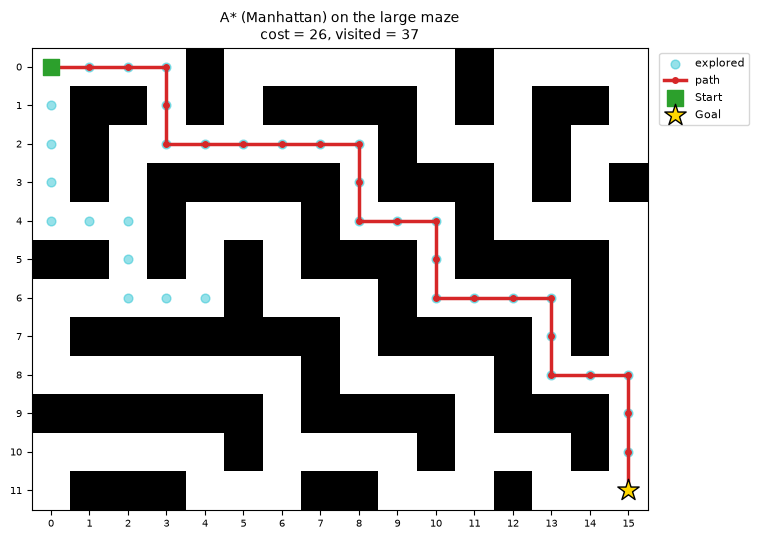

In [9]:
res_astar = search_grid(big_maze, big_start, big_goal, mode="astar")

print("Path length (moves):", res_astar["path_length"])
print("Visited states:     ", res_astar["visited"])
print("Free cells in maze: ", int((big_maze == 0).sum()))
print(f"Runtime:             {res_astar['runtime_ms']:.3f} ms")

plot_search(big_maze, res_astar, big_start, big_goal, "A* (Manhattan) on the large maze")

### Extension 1: BFS vs. A\* on the same maze

Both algorithms are optimal here (every step costs 1), so they must return paths of the same length. The interesting difference is how many cells they have to explore.

algorithm   length  visited  time [ms]
BFS             26      107      0.409
A*              26       37      0.094


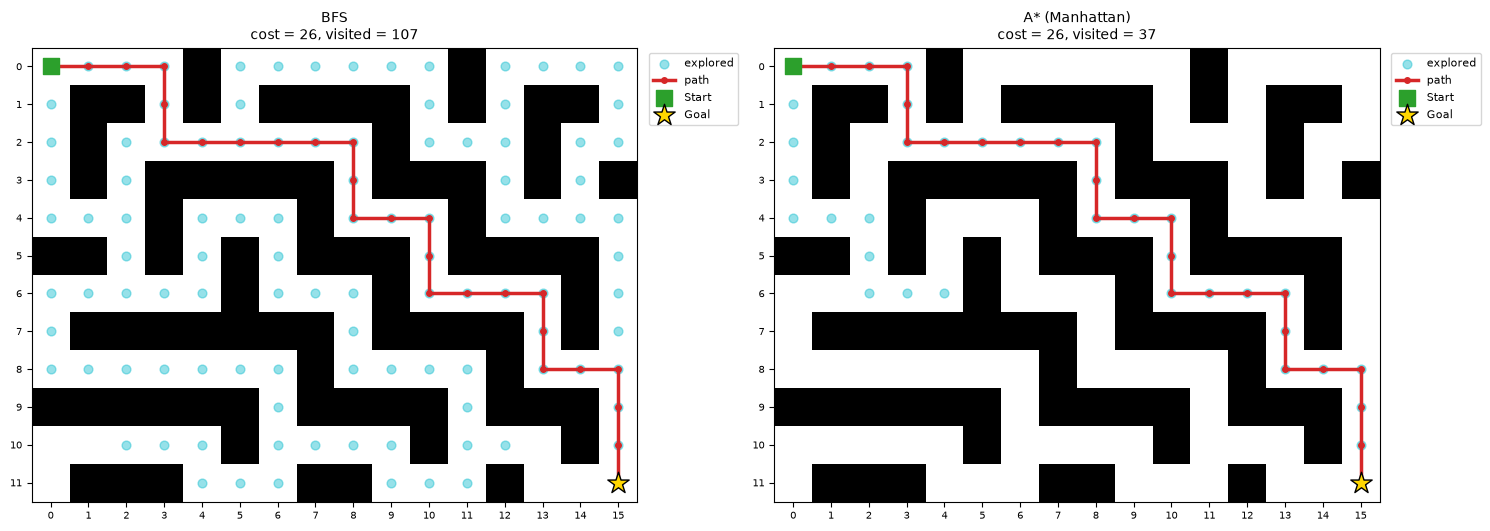

In [10]:
res_bfs = search_grid(big_maze, big_start, big_goal, mode="bfs")

print(f"{'algorithm':<10} {'length':>7} {'visited':>8} {'time [ms]':>10}")
for name, r in [("BFS", res_bfs), ("A*", res_astar)]:
    print(f"{name:<10} {r['path_length']:>7} {r['visited']:>8} {r['runtime_ms']:>10.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_search(big_maze, res_bfs, big_start, big_goal, "BFS", ax=axes[0])
plot_search(big_maze, res_astar, big_start, big_goal, "A* (Manhattan)", ax=axes[1])
plt.tight_layout()
plt.show()

### Extension 2: Diagonal movement

In the large maze all corridors are one cell wide, so diagonal steps would not help there (cutting corners between two walls is not allowed). That is why diagonal movement is shown on a more open "room" with a few walls.

With 8 directions a diagonal step costs √2. Manhattan distance would now *overestimate* (one diagonal step of cost 1.41 covers a Manhattan distance of 2), so it is no longer admissible. The correct heuristic for this case is the **octile distance**: `max(dx, dy) + (√2 - 1) * min(dx, dy)`.

4 directions (Manhattan): moves = 22, cost = 22, visited = 98
8 directions (octile):    moves = 15, cost = 17.90, visited = 48


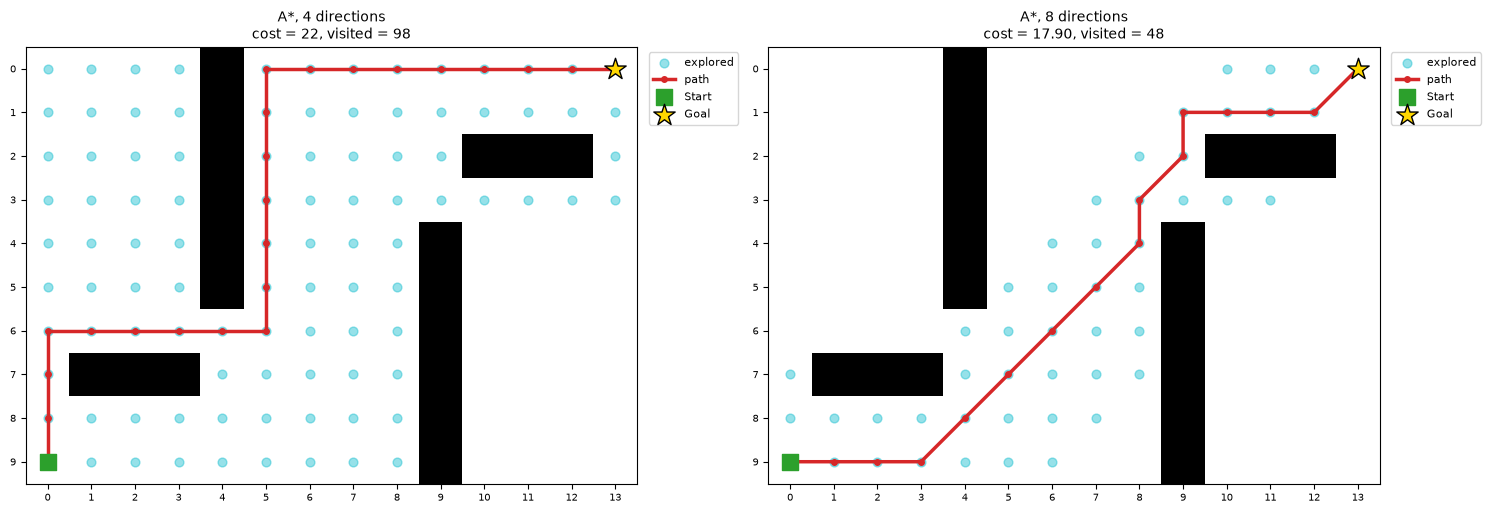

In [11]:
def octile(a, b):
    dx, dy = abs(a[0] - b[0]), abs(a[1] - b[1])
    return max(dx, dy) + (math.sqrt(2) - 1) * min(dx, dy)

room = np.zeros((10, 14), dtype=int)
room[0:6, 4] = 1
room[4:10, 9] = 1
room[2, 10:13] = 1
room[7, 1:4] = 1
room_start, room_goal = (9, 0), (0, 13)

res_4dir = search_grid(room, room_start, room_goal, mode="astar")
res_8dir = search_grid(room, room_start, room_goal, mode="astar", heuristic=octile, diagonal=True)

print(f"4 directions (Manhattan): moves = {res_4dir['path_length']}, cost = {res_4dir['cost']}, visited = {res_4dir['visited']}")
print(f"8 directions (octile):    moves = {res_8dir['path_length']}, cost = {res_8dir['cost']:.2f}, visited = {res_8dir['visited']}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_search(room, res_4dir, room_start, room_goal, "A*, 4 directions", ax=axes[0])
plot_search(room, res_8dir, room_start, room_goal, "A*, 8 directions", ax=axes[1])
plt.tight_layout()
plt.show()

### Extension 3: Weighted cells

Some cells are now "mud" and cost 5 to enter instead of 1. BFS ignores costs, so it still takes the route with the fewest steps, straight through the mud. A\* minimises the total cost, so it walks around. Manhattan distance stays admissible because every cell costs at least 1.

BFS: moves = 26, total cost = 86
A* : moves = 32, total cost = 32


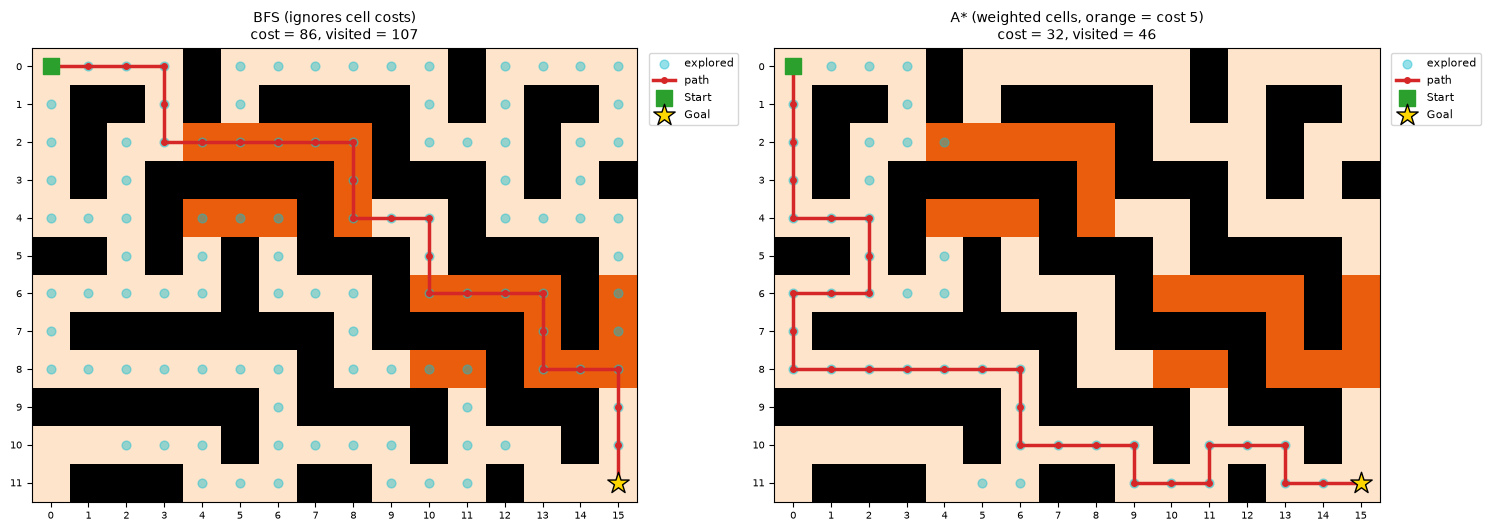

In [12]:
weights = np.ones_like(big_maze)
weights[6:9, 10:16] = 5     # muddy area near the goal
weights[2:5, 4:9] = 5       # muddy area in the upper middle

res_w_bfs = search_grid(big_maze, big_start, big_goal, mode="bfs", cell_cost=weights)
res_w_astar = search_grid(big_maze, big_start, big_goal, mode="astar", cell_cost=weights)

print(f"BFS: moves = {res_w_bfs['path_length']}, total cost = {res_w_bfs['cost']}")
print(f"A* : moves = {res_w_astar['path_length']}, total cost = {res_w_astar['cost']}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_search(big_maze, res_w_bfs, big_start, big_goal, "BFS (ignores cell costs)", ax=axes[0], cell_cost=weights)
plot_search(big_maze, res_w_astar, big_start, big_goal, "A* (weighted cells, orange = cost 5)", ax=axes[1], cell_cost=weights)
plt.tight_layout()
plt.show()

### Extension 4: A maze where Greedy makes a bad choice

The maze below is full of short walls and dead ends. Start is on the left, goal on the right in the same row. Greedy always steps onto the cell that is closest to the goal *in a straight line*, so it keeps pushing right, runs into walls and has to wriggle around them. Whatever path it stumbled along is the path it returns. A\* also counts the steps already taken, so it notices when a "promising" route has become too long and switches to a better one.

Greedy: path length = 37, visited = 49
A*    : path length = 21, visited = 62


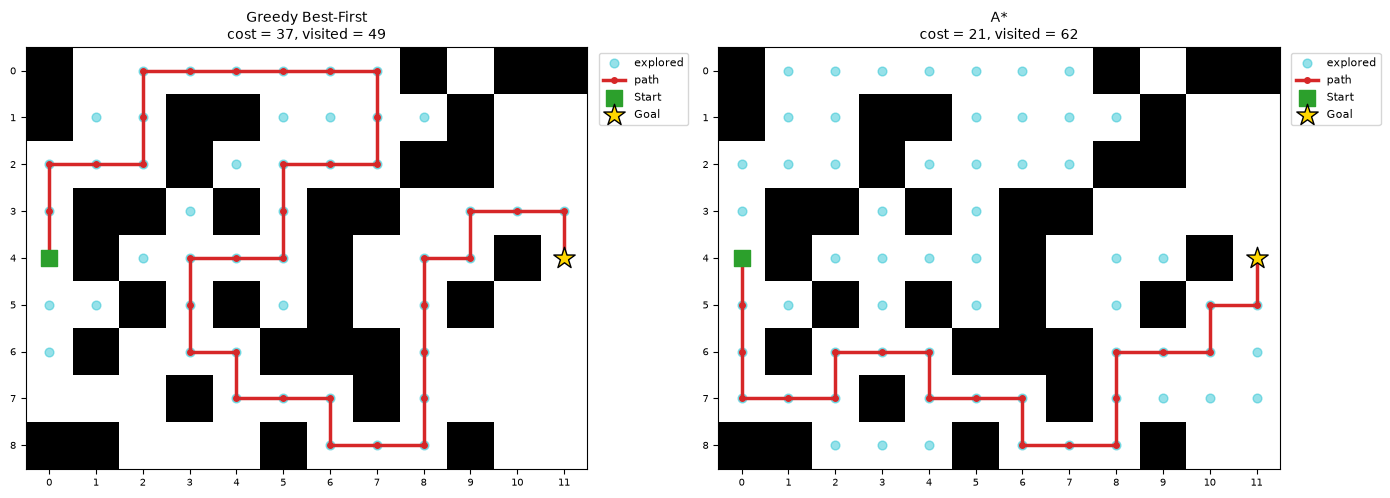

In [13]:
trap_maze = np.array([
    [1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1],
    [1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0],
    [0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0],
    [0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0],
    [0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0],
    [0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0],
    [1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0],
])

trap_start = (4, 0)
trap_goal = (4, 11)

res_t_greedy = search_grid(trap_maze, trap_start, trap_goal, mode="greedy")
res_t_astar = search_grid(trap_maze, trap_start, trap_goal, mode="astar")

print(f"Greedy: path length = {res_t_greedy['path_length']}, visited = {res_t_greedy['visited']}")
print(f"A*    : path length = {res_t_astar['path_length']}, visited = {res_t_astar['visited']}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_search(trap_maze, res_t_greedy, trap_start, trap_goal, "Greedy Best-First", ax=axes[0])
plot_search(trap_maze, res_t_astar, trap_start, trap_goal, "A*", ax=axes[1])
plt.tight_layout()
plt.show()

### Mini project: conclusions

| experiment | result |
|---|---|
| A\* vs. BFS, large maze | same optimal length (26 moves), but A\* explored 37 cells and BFS 107 |
| 4 vs. 8 directions | diagonal moves shorten the route from 22 to about 17.9; octile distance keeps A\* admissible |
| weighted cells | BFS walks through the mud (cost 86), A\* goes around it (32 moves, cost 32) |
| Greedy trap | Greedy needed 37 moves, A\* only 21 |

- On a uniform grid BFS and A\* both find the shortest path. The heuristic does not change *what* A\* finds, only *how much work* it takes to find it.
- As soon as steps have different costs, BFS is no longer optimal, because it minimises the number of steps and not the total cost.
- Greedy is fast and explores few cells, but it can be led into long detours since it ignores the cost already paid.
- The heuristic has to match the movement model: Manhattan for 4 directions, octile for 8 directions. Otherwise it may overestimate and A\* loses its guarantee.